# Viernheim WG Flat: 100% or 90% Financing, Against an ETF and a Rürup Top-Up

A real offer, modelled in the engine: a furnished five-room WG flat in
Viernheim, 114.88 m², 470,000 €, five tenancy contracts worth 2,345 € a month
cold from October 2026, and a bank willing to finance 90% at about 4.7%. The
broker's own sheets (`data/buy_wg/`, out of git) show an "Eigenkapitalrendite"
of 28% on the 101,379 € of equity the 90% loan needs; their arithmetic is taken
apart in `data/buy_wg/razbor_rascheta_lucasa.md`. This notebook asks the
question those sheets cannot: against *what*?

Four worlds, the same household in each — the same salaries, the same
spending, the same 110,000 € on day one, the same Basisrente contract already
running. They differ only in where the money goes:

1. **ETF only** — everything left at the end of a month goes into a broad ETF.
2. **Flat, 100% financed** — the bank lends the price; only the 11.57% of
   purchase fees come out of the ETF.
3. **Flat, 90% financed** — what the bank actually offers: 10% of the price
   plus the fees, 101,379 €, come out of the ETF.
4. **ETF + Rürup top-up** — a raise of the existing Basisrente, booked the way
   the insurer books one; the tax it saves comes back every July into the ETF.

All four run to the year you turn 100, retirement included, as in
[`ruerup_vs_etf.ipynb`](ruerup_vs_etf.ipynb). The flat is never sold: a
snapshot "if sold" takes the property value less 3% selling costs less the
loan. The measure is each world's *lead over the ETF-only world*, wealth being
the ETF after the tax a sale would cost, plus the tax settlement still due,
plus the flat's net value. The Basisrente's value never counts as wealth (it can
only ever become a pension), so the Rürup world is judged by its break-even age
instead, the age at which its wealth catches up.

These are model results under stated assumptions, not advice. Two assumptions
carry the whole result: that the 8.85% depreciation the broker promises (a 5%
Sonder-AfA for four years on top of 3.85%) passes the Finanzamt, and that
470,000 € is what the flat is worth. Section 3 shows what happens when they do
not hold.

In [1]:
from pathlib import Path
import sys

ROOT_DIR = Path.cwd().resolve().parent
sys.path.append(str(ROOT_DIR))

import pandas as pd
from matplotlib import pyplot as plt

from src.model import (
    Earner,
    Etf,
    FinancialModel,
    GermanHousehold,
    InvestmentProperty,
    Mortgage,
    OperatingCosts,
    PrivateHealthInsurance,
    RentalTaxation,
    Retirement,
    RuerupAnnuity,
    RuerupPension,
    Spending,
)
from src.model.german_tax import TaxSystem, basisrente_cap, social_contributions

## Assumptions

**The household.** You earn 100,000 € (the May and October 2026 payslips,
HanseMerkur private insurance); your spouse 103,000 €, a placeholder, on the
same private contract, another placeholder. Both salaries follow wages at 3.3%
a year; Steuerklasse IV/IV; no children. Spending of 4,000 € a month in
today's money, growing with 2% inflation, and 110,000 € of liquid money on day
one are placeholders too. Every world shares them, so they cancel out of the
comparison; they only decide whether a world ever has to sell shares to pay
its bills, and none does. Retirement as in `ruerup_vs_etf`: you at 67 in
November 2063, your spouse 52 months earlier, both statutory pensions from the
insurer's estimate.

**The flat.** 470,000 €, purchase fees 11.57% (Makler 3.57%, Notar 1.5%,
Grundbuch 0.5%, Grunderwerbsteuer 6%), building share 80%. Rent: the five
contracts' 2,345 € cold from October 2026; their Staffel (+75 € a year for six
years, then 2%) is taken as 2.5% a year. The tenants' 450 € Pauschale is
assumed to cover what it is for, so only the non-recoverable costs remain:
200 € a month deductible (the non-recoverable Hausgeld, the Grundsteuer, the
management fee net of the Pauschale), plus 211 € set aside without a
deduction — the WEG reserve of 55 €, the 56 € own reserve the broker's sheet
recommends and then sets to zero, and 100 € for the furniture five rooms wear
out. Vacancy 5%. The price grows 2% a year, the costs 2%.

**The loan.** 4.7% (Lucas: "between 4.5 and 4.7"), 1.3% initial Tilgung, and
the annuity stays constant until the loan is repaid, in 2058 as in the
broker's sheet. 100% financed the payment is 2,350 € a month, 90% financed
2,115 €. The engine knows no change of rate at the end of a Zinsbindung; the
5.5% row in section 3 stands in for a dearer Anschlussfinanzierung.

**The depreciation.** The base case takes the broker at his word: 8.85% for
four years, 3.85% after, on 80% of price plus fees, until the building is
written off in year 21. Neither rate is confirmed in writing; 3.85% alone and
the statutory 2% run alongside.

**The Basisrente.** The signed NÜRNBERGER contract, 500 € a month with 14
months paid before January 2026, in every world. The top-up is a second
contract for the remaining 454 months at the same tariff, paying the declared
2024 annuity basis. The funds cost 0.38% a year.

**The ETF.** A broad world ETF at 0.20% TER, taxed at 26.375% on 70% of the
gain (Teilfreistellung) on every sale. Market return 6% a year in the base
case, 4% and 8% alongside; the Basisrente's funds see the same market.

**The calendar.** The engine's first year is 2026, the year its tax law is
enacted for, so the flat is bought in January 2026, a year before it could
really happen. The tax parameters drift by inertia, so the shift changes
nothing worth seeing.

In [2]:
SYSTEM = TaxSystem(rich_threshold_frozen=False)   # 2026 law, drifting by inertia to 2096
INFLATION = 0.02
WAGE_GROWTH = SYSTEM.yearly_wage_growth

# --- the household -----------------------------------------------------------
YOUR_GROSS = 100_000.0              # May and October 2026 payslips
SPOUSE_GROSS = 103_000.0            # placeholder
HANSEMERKUR = PrivateHealthInsurance(
    monthly_premium=638.0, monthly_care_premium=57.0, deductible_share=349.0 / 638.0, monthly_rebate=182.95
)
SPOUSE_PRIVATE = HANSEMERKUR        # placeholder: the same contract assumed
N_CHILDREN = 0
SPENDING = 4_000.0                  # placeholder, today's euros, follows inflation
START_CAPITAL = 110_000.0           # placeholder: liquid money on day one, the same in every world

WORKING_MONTHS = 454                # January 2026 – October 2063; you turn 67 in November 2063
SPOUSE_EARLIER = 52                 # months: your spouse retires in mid-2059
YOUR_POINTS = 9_882 / 124.53        # the insurer's pension estimate, in Entgeltpunkte
SPOUSE_POINTS = 8_524 / 124.53
YEARS = 71                          # to December 2096, the year you turn 100
AT_67 = 38                          # the year-38 row is December 2063
START_AGE = 67 - AT_67

# --- the flat ----------------------------------------------------------------
PRICE = 470_000.0
AREA = 114.88
COLD_RENT = 2_345.0                 # five contracts from 1 October 2026, Nettokaltmiete
RENT_GROWTH = 0.025                 # Staffel +75 €/yr for six years, then 2%
DEDUCTIBLE = 200.0                  # non-recoverable costs net of the 450 € Pauschale, Grundsteuer
OWN_RESERVE = 55.0 + 56.0 + 100.0   # WEG reserve, own reserve, furniture: cash, not deductible
COST_GROWTH = 0.02
VACANCY = 0.05
PRICE_GROWTH = 0.02
BUILDING_SHARE = 0.80
FEES = 0.1157                       # Makler 3.57% + Notar 1.5% + Grundbuch 0.5% + GrESt 6%
FEES_NO_AGENT = 0.08
RATE = 0.047
TILGUNG = 0.013                     # the annuity then stays constant until the loan is repaid
SELLING_COSTS = 0.03                # what a snapshot sale costs
AFA_CASES = {
    "8.85% → 3.85%": RentalTaxation(
        afa_rate=0.0385, building_share=BUILDING_SHARE, special_afa_rate=0.05, special_afa_years=4
    ),
    "3.85%": RentalTaxation(afa_rate=0.0385, building_share=BUILDING_SHARE),
    "2%": RentalTaxation(afa_rate=0.02, building_share=BUILDING_SHARE),
}
AFA = "8.85% → 3.85%"               # the base case: the broker's promise holds

# --- the Basisrente ----------------------------------------------------------
MONTHLY = 500.0
TERM = 468
ELAPSED = 14
DECLARED = RuerupAnnuity(factor=24.996271, bonus_rate=0.0187)   # 2024 basis, not promised
FUND_COSTS = 0.0038
TOP_UP = 1_000.0                    # the Rürup world's raise in sections 2 and 5

# --- the ETF and the market --------------------------------------------------
MARKET = 0.06
MARKETS = (0.04, 0.06, 0.08)
ETF_TER = 0.0020
ETF_TAX = 0.26375 * 0.7             # Abgeltungsteuer + Soli with 30% Teilfreistellung

room = basisrente_cap(SYSTEM, joint=True) - 12.0 * MONTHLY
for gross in (YOUR_GROSS, SPOUSE_GROSS):
    room -= 2.0 * social_contributions(gross, SYSTEM, n_children=N_CHILDREN, private_health=True).pension
TOP_UPS = (500.0, 1_000.0, round(room / 12.0))
print(f"Deduction room left in 2026: €{room:,.0f} a year, €{room / 12:,.0f} a month")

Deduction room left in 2026: €18,192 a year, €1,516 a month


In [3]:
def fund_return(market: float, costs: float) -> float:
    # A fund's own growth: the market return less the fund's costs.
    return (1.0 + market) * (1.0 - costs) - 1.0


def household() -> GermanHousehold:
    return GermanHousehold(
        earners=(
            Earner(
                monthly_gross=YOUR_GROSS / 12,
                yearly_increase_rate=WAGE_GROWTH,
                private_health=HANSEMERKUR,
                retirement=Retirement.from_entgeltpunkte(YOUR_POINTS, working_months=WORKING_MONTHS),
            ),
            Earner(
                monthly_gross=SPOUSE_GROSS / 12,
                yearly_increase_rate=WAGE_GROWTH,
                private_health=SPOUSE_PRIVATE,
                retirement=Retirement.from_entgeltpunkte(
                    SPOUSE_POINTS, working_months=WORKING_MONTHS - SPOUSE_EARLIER
                ),
            ),
        ),
        tax_classes="IV/IV",
        n_children=N_CHILDREN,
        tax=SYSTEM,
    )


def contract(market: float) -> RuerupPension:
    return RuerupPension(
        monthly_contribution=MONTHLY,
        contribution_months=TERM,
        yearly_return_rate=fund_return(market, FUND_COSTS),
        elapsed_months=ELAPSED,
        annuity=DECLARED,
        name="ruerup",
    )


def top_up(amount: float, market: float) -> RuerupPension:
    return RuerupPension(
        monthly_contribution=amount,
        contribution_months=WORKING_MONTHS,
        yearly_return_rate=fund_return(market, FUND_COSTS),
        annuity=DECLARED,
        name="top_up",
    )


def etf(market: float) -> Etf:
    return Etf(initial_capital=START_CAPITAL, yearly_return_rate=fund_return(market, ETF_TER), tax_rate=ETF_TAX)


def flat(
    ltv: float,
    *,
    fees: float = FEES,
    afa=AFA,
    price: float = PRICE,
    rent: float = COLD_RENT,
    rate: float = RATE,
    vacancy: float = VACANCY,
    reserve: float = OWN_RESERVE,
    deductible: float = DEDUCTIBLE,
) -> InvestmentProperty:
    return InvestmentProperty(
        price=price,
        yearly_price_increase_rate=PRICE_GROWTH,
        monthly_rental_income=rent,
        yearly_rental_income_increase_rate=RENT_GROWTH,
        mortgage=Mortgage(
            interest_rate=rate,
            down_payment_rate=1.0 - ltv,
            fees_rate=fees,
            yearly_repayment_rate=TILGUNG,
        ),
        operating_costs=OperatingCosts(
            monthly_deductible=deductible, monthly_own_reserve=reserve, yearly_increase_rate=COST_GROWTH
        ),
        vacancy_rate=vacancy,
        taxation=AFA_CASES[afa] if isinstance(afa, str) else afa,
        name="flat",
    )


def world(*extras, market: float = MARKET, years: int = YEARS) -> pd.DataFrame:
    parts = [household(), Spending(monthly_amount=SPENDING), contract(market), etf(market), *extras]
    model = FinancialModel(parts, years=years, start_age=START_AGE, yearly_inflation_rate=INFLATION)
    frame = model.run().set_index("year")
    assert not (frame["etf_capital"] < 0).any(), "a world ran out of money"
    return frame


def settlement(frame: pd.DataFrame) -> pd.Series:
    # Due next July: what was withheld and paid in advance, less the assessed tax.
    return (
        frame["household.yearly_withheld_tax"]
        + frame["household.yearly_prepaid_tax"]
        - frame["household.yearly_assessed_tax"]
    )


def wealth(frame: pd.DataFrame) -> pd.Series:
    # The ETF after the tax a sale would cost, the settlement due, and the flat if sold.
    total = frame["etf_capital_after_tax"] + settlement(frame)
    if "flat.property_value" in frame:
        total = total + frame["flat.property_value"] * (1.0 - SELLING_COSTS) - frame["flat.total_loan"]
    return total


def lead(frame: pd.DataFrame, base: pd.DataFrame) -> pd.Series:
    return wealth(frame) - wealth(base)


def overtakes(frame: pd.DataFrame, base: pd.DataFrame):
    # The first year in which this world is ahead of the base world.
    ahead = lead(frame, base)
    for year in range(1, len(ahead)):
        if ahead[year] > 0.0:
            return year
    return None


def break_even(frame: pd.DataFrame, base: pd.DataFrame):
    # The age at which a Rürup world's wealth catches up with the base world's.
    behind = -lead(frame, base)
    if behind[AT_67] <= 0.0:
        return 67.0
    for year in range(AT_67 + 1, len(behind)):
        if behind[year] <= 0.0:
            before, after = behind[year - 1], behind[year]
            return frame.loc[year - 1, "age"] + before / (before - after)
    return None


def todays(amount: float, year: int) -> float:
    return amount / (1.0 + INFLATION) ** year


def eur(amount: float) -> str:
    return f"€{amount:,.0f}"


def age(value) -> str:
    return "after 100" if value is None else f"{value:.1f}"


def year_label(year) -> str:
    return "never" if year is None else f"year {year} ({2025 + year})"

## 1. The Flat in the Engine

First the broker's sheet inside the engine. With his inputs — 2,815 € in the
rent field (the cold rent plus the Pauschale), 673 € of costs, no vacancy, no
reserve, 8.85% depreciation — his "Jahre 1–4" sheet shows an operating cash
flow of 27 € a month and a 1,096 € tax refund: 1,123 € a month after tax. The
engine, run with the same inputs but this household's real tariff:

In [4]:
lucas = world(
    flat(
        0.9,
        afa=RentalTaxation(afa_rate=0.0885, building_share=BUILDING_SHARE),
        rent=2_815.0,
        vacancy=0.0,
        reserve=0.0,
        deductible=673.0,
    ),
    years=2,
)
alone = world(years=2)
operating = lucas.loc[1, "flat.cumulative_cashflow"] - lucas.loc[0, "flat.cumulative_cashflow"]
tax_effect = alone.loc[1, "household.yearly_assessed_tax"] - lucas.loc[1, "household.yearly_assessed_tax"]
pd.DataFrame(
    {
        "broker's sheet": [eur(12 * 27), eur(12 * 1_096), eur(12 * 1_123), eur(1_123), "42%"],
        "engine": [eur(operating), eur(tax_effect), eur(operating + tax_effect), eur((operating + tax_effect) / 12),
                   f"{tax_effect / -lucas.loc[1, 'flat.yearly_taxable_result']:.1%}"],
    },
    index=["operating cash flow, year 1", "tax effect", "after tax", "after tax, a month", "tax rate on the loss"],
)

,broker's sheet,engine
"operating cash flow, year 1",€324,€324
tax effect,"€13,152","€14,198"
after tax,"€13,476","€14,522"
"after tax, a month","€1,123","€1,210"
tax rate on the loss,42%,45.5%


Now with the notebook's own inputs, the 90% world year by year: the cold rent
net of vacancy, all costs, interest, depreciation, the flat's taxable result,
what it does to the household's income tax (positive: a refund), the cash the
flat leaves after that tax, the loan, and the lead over the ETF-only world.
Monthly figures are the year's averages.

In [5]:
etf_only = world()
flat_90 = world(flat(0.9))
flat_100 = world(flat(1.0))

operating = flat_90["flat.cumulative_cashflow"].diff()
tax_effect = etf_only["household.yearly_assessed_tax"] - flat_90["household.yearly_assessed_tax"]
ahead = lead(flat_90, etf_only)
rows = []
for year in (1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 21, 25, 30, AT_67):
    row = flat_90.loc[year]
    rows.append(
        {
            "year": f"{year} ({2025 + year})",
            "rent": eur(row["flat.monthly_rental_income"]),
            "costs": eur(row["flat.monthly_operating_costs"]),
            "interest": eur(row["flat.monthly_interest_payment"]),
            "AfA": eur(row["flat.monthly_afa"]),
            "taxable result": eur(row["flat.yearly_taxable_result"]),
            "tax effect": eur(tax_effect[year]),
            "cash after tax": eur(operating[year] + tax_effect[year]),
            "loan": eur(row["flat.total_loan"]),
            "lead over ETF": eur(ahead[year]),
        }
    )
print(f"Lead on day one: {eur(ahead[0])} — the fees and the 3% a sale would cost")
pd.DataFrame(rows).set_index("year")

Lead on day one: €-68,479 — the fees and the 3% a sale would cost


,rent,costs,interest,AfA,taxable result,tax effect,cash after tax,loan,lead over ETF
year,,,,,,,,,
1 (2026),"€2,228",€411,"€1,647","€3,094","€-32,554","€14,774","€11,195","€417,381","€-47,408"
2 (2027),"€2,283",€419,"€1,624","€3,094","€-31,664","€14,511","€11,502","€411,492","€-25,731"
3 (2028),"€2,341",€428,"€1,601","€3,094","€-30,745","€14,244","€11,819","€405,320","€-2,995"
4 (2029),"€2,399",€436,"€1,576","€3,094","€-29,796","€13,970","€12,145","€398,852","€20,857"
5 (2030),"€2,459",€445,"€1,550","€1,346","€-7,842","€3,686","€2,476","€392,074","€35,881"
6 (2031),"€2,520",€454,"€1,523","€1,346","€-6,830","€3,209","€2,630","€384,969","€51,761"
8 (2033),"€2,648",€472,"€1,465","€1,346","€-4,708","€2,213","€2,945","€369,721","€85,419"
10 (2035),"€2,782",€491,"€1,401","€1,346","€-2,443","€1,148","€3,260","€352,972","€121,774"
12 (2037),"€2,923",€511,"€1,331","€1,346",€-25,€11,"€3,575","€334,577","€161,043"


Three things the sheet does not show. The tax effect is more than 42% of the
loss: this household's income tax sits in the Solidaritätszuschlag's
Milderungszone, where every euro of tax also moves 11.9 cents of Soli, so a
rental loss is worth about 45 cents on the euro — more than the broker's flat
42%. The refund drops to a quarter in year 5 when the Sonder-AfA ends, and the
cash flow with it; from year 13 the flat makes a taxable profit, and from year
22, the building written off, the whole rent less interest and costs is
taxed — so that between the write-off and the 2058 payoff the flat asks the
household for a little cash each year, the rent covering the annuity but not
the tax on a profit the AfA no longer shelters, and only once the loan is gone
does it pay about 27,000 € a year. And the lead over the ETF-only world
starts at −68,000 €, the fees plus the 3% a sale would cost, and turns
positive in year 4.

## 2. Four Worlds

The lead of each world over the ETF-only world at the horizons that matter: ten
years, when a sale becomes tax-free; fifteen; twenty; the end of 2063, when you
turn 67; and the end of 2096. Nominal euros, the 67 column also in today's
money, deflated at 2% a year. The Rürup world raises the contract by 1,000 € a
month here; section 4 varies that.

In [6]:
ruerup_world = world(top_up(TOP_UP, MARKET))
worlds = {
    "flat, 100% financed": flat_100,
    "flat, 90% financed": flat_90,
    f"ETF + Rürup top-up {TOP_UP:,.0f} €": ruerup_world,
}
HORIZONS = ((10, "10 years"), (15, "15 years"), (20, "20 years"), (AT_67, "at 67"), (YEARS, "at 100"))

rows = []
for name, frame in worlds.items():
    ahead = lead(frame, etf_only)
    row = {"world": name}
    for year, label in HORIZONS:
        row[label] = eur(ahead[year])
    row["at 67, today's €"] = eur(todays(ahead[AT_67], AT_67))
    if "top_up.contract_value" in frame:
        row["ahead of ETF-only from"] = f"break-even at {age(break_even(frame, etf_only))}"
    else:
        row["ahead of ETF-only from"] = year_label(overtakes(frame, etf_only))
    rows.append(row)
scale = {"world": "ETF-only wealth, for scale"}
for year, label in HORIZONS:
    scale[label] = eur(wealth(etf_only)[year])
scale["at 67, today's €"] = eur(todays(wealth(etf_only)[AT_67], AT_67))
scale["ahead of ETF-only from"] = ""
rows.append(scale)
pd.DataFrame(rows).set_index("world")

,10 years,15 years,20 years,at 67,at 100,"at 67, today's €",ahead of ETF-only from
world,,,,,,,
"flat, 100% financed","€133,654","€246,719","€384,422","€983,022","€5,693,713","€463,187",year 4 (2029)
"flat, 90% financed","€121,774","€225,940","€352,255","€878,734","€5,002,043","€414,048",year 4 (2029)
"ETF + Rürup top-up 1,000 €","€-84,563","€-145,528","€-224,393","€-760,537","€-1,519,493","€-358,355",break-even at after 100
"ETF-only wealth, for scale","€1,259,033","€2,243,731","€3,641,632","€14,506,296","€100,303,895","€6,835,181",


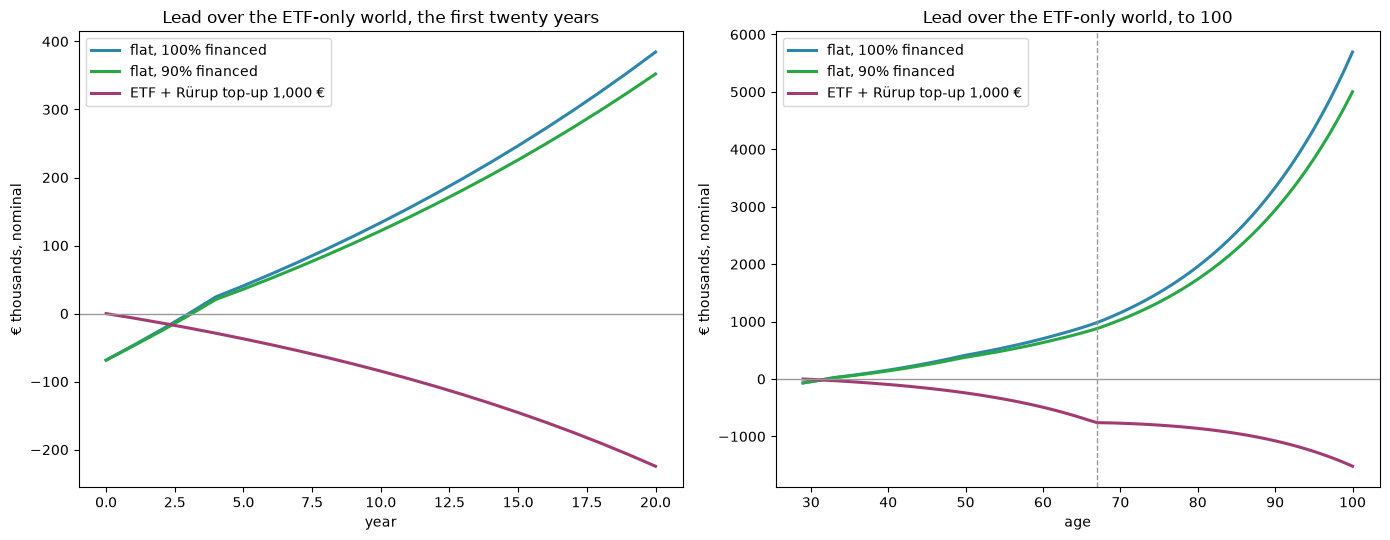

In [7]:
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 5.5))
colors = {"flat, 100% financed": "#2E86AB", "flat, 90% financed": "#28A745", f"ETF + Rürup top-up {TOP_UP:,.0f} €": "#A23B72"}
for name, frame in worlds.items():
    ahead = lead(frame, etf_only)
    left.plot(ahead.index[:21], ahead.iloc[:21] / 1000, color=colors[name], lw=2.2, label=name)
    right.plot(frame["age"], ahead / 1000, color=colors[name], lw=2.2, label=name)
for axis in (left, right):
    axis.axhline(0, color="#999999", lw=1)
    axis.set_ylabel("€ thousands, nominal")
    axis.legend()
left.set_title("Lead over the ETF-only world, the first twenty years")
left.set_xlabel("year")
right.set_title("Lead over the ETF-only world, to 100")
right.set_xlabel("age")
right.axvline(67, color="#999999", lw=1, ls="--")
plt.tight_layout()
plt.show()

Under the base assumptions both flat worlds beat the ETF-only world: by about
120,000 € after ten years, and by 880,000 to 980,000 € nominal — 410,000 to
460,000 € in today's money — by 67. The 100% world leads the 90% world by
12,000 € at ten years and 104,000 € at 67. At 4.7% the interest is deductible
at 45 cents on the euro, so borrowing more and leaving the equity in a 6%
market pays; the bank has said no to that, and the cost of its no is what
separates the two lines. The Rürup top-up trails the ETF-only world by
760,000 € at 67 and never catches up by 100 at a 6% market; at 3% it would,
at about 96, as `ruerup_vs_etf` found.

## 3. What the Flat Depends On

The same leads for the 90% and the 100% worlds with one assumption changed at
a time, and the year each flat world first pulls ahead of the ETF-only world.

The price needs a word. The engine values the flat at what was paid and grows
that at 2%, so paying less barely moves the lead: less equity and interest,
but also less depreciation and a smaller value. What matters is paying more
than the flat is worth, and Lucas himself writes that the bank values it below
470,000 €. The engine cannot represent that, so the "worth" rows subtract the
gap, grown at 2% and net of selling costs, from the lead after the fact.

In [8]:
SCENARIOS = [
    ("base case", {}, {}),
    ("AfA 3.85% only (no §7b)", dict(afa="3.85%"), {}),
    ("AfA 2% only (no Gutachten either)", dict(afa="2%"), {}),
    ("market return 4%", {}, dict(market=0.04)),
    ("market return 8%", {}, dict(market=0.08)),
    ("loan at 4.5%", dict(rate=0.045), {}),
    ("loan at 5.5% for good", dict(rate=0.055), {}),
    ("no Makler fee (fees 8%)", dict(fees=FEES_NO_AGENT), {}),
    ("no vacancy", dict(vacancy=0.0), {}),
    ("vacancy 10%", dict(vacancy=0.10), {}),
    ("rent 1,850 € (defensible WG rent)", dict(rent=1_850.0), {}),
    ("rent 1,260 € (the sheet's own market rent)", dict(rent=1_260.0), {}),
    ("price 440,000 €, worth the same", dict(price=440_000.0), {}),
    ("the broker's inputs: 2,815 € rent, 673 € costs, no vacancy, no reserve",
     dict(rent=2_815.0, deductible=673.0, vacancy=0.0, reserve=0.0), {}),
    ("AfA 2% and rent 1,850 €", dict(afa="2%", rent=1_850.0), {}),
]
POINTS = ((10, "10 y"), (20, "20 y"), (AT_67, "67"))

rows = []
bases = {MARKET: etf_only}
for label, flat_changes, world_changes in SCENARIOS:
    market = world_changes.get("market", MARKET)
    if market not in bases:
        bases[market] = world(market=market)
    base = bases[market]
    row = {"scenario": label}
    for ltv, tag in ((0.9, "90%"), (1.0, "100%")):
        frame = world(flat(ltv, **flat_changes), **world_changes)
        ahead = lead(frame, base)
        for year, point in POINTS:
            row[f"{tag}: {point}"] = eur(ahead[year])
        row[f"{tag}: ahead from"] = year_label(overtakes(frame, base))
    rows.append(row)

# Paid the price, worth less: the gap leaves the lead after the fact.
for worth in (423_000.0, 400_000.0, 360_000.0):
    row = {"scenario": f"paid 470,000 €, worth {worth:,.0f} €"}
    for ltv, tag, frame in ((0.9, "90%", flat_90), (1.0, "100%", flat_100)):
        ahead = lead(frame, etf_only) - (PRICE - worth) * (1.0 + PRICE_GROWTH) ** ahead.index * (1.0 - SELLING_COSTS)
        for year, point in POINTS:
            row[f"{tag}: {point}"] = eur(ahead[year])
        first = next((year for year in range(1, len(ahead)) if ahead[year] > 0.0), None)
        row[f"{tag}: ahead from"] = year_label(first)
    rows.append(row)
pd.DataFrame(rows).set_index("scenario")

,90%: 10 y,90%: 20 y,90%: 67,90%: ahead from,100%: 10 y,100%: 20 y,100%: 67,100%: ahead from
scenario,,,,,,,,
base case,"€121,774","€352,255","€878,734",year 4 (2029),"€133,654","€384,422","€983,022",year 4 (2029)
AfA 3.85% only (no §7b),"€68,586","€264,232","€728,404",year 6 (2031),"€81,070","€297,398","€835,385",year 6 (2031)
AfA 2% only (no Gutachten either),"€24,197","€146,229","€442,342",year 8 (2033),"€36,683","€179,644","€550,020",year 7 (2032)
market return 4%,"€139,740","€396,475","€1,026,740",year 3 (2028),"€142,183","€403,291","€1,045,642",year 3 (2028)
market return 8%,"€99,935","€284,198","€530,000",year 4 (2029),"€123,133","€354,272","€831,014",year 4 (2029)
loan at 4.5%,"€127,604","€366,766","€925,090",year 4 (2029),"€140,139","€400,576","€1,034,611",year 3 (2028)
loan at 5.5% for good,"€98,464","€294,571","€699,661",year 4 (2029),"€107,718","€320,212","€783,738",year 4 (2029)
no Makler fee (fees 8%),"€144,476","€387,264","€971,122",year 3 (2028),"€156,393","€419,505","€1,075,607",year 3 (2028)
no vacancy,"€133,125","€384,947","€1,005,942",year 4 (2029),"€145,066","€417,263","€1,110,627",year 3 (2028)


The sign at ten years survives most single changes: the lower depreciation, a
dearer loan, an 8% market, a vacancy of 10%, a flat worth 400,000 €. It does
not survive the rent falling to what the broker's own calculator calls the
market rent for this flat as an ordinary one, 1,260 €: the lead is then small
at ten years and negative by 67 — the flat earns its lead from the WG premium,
not from being a flat. A flat worth 360,000 €, about 3,100 €/m², where
comparable Viernheim flats trade, is behind at ten years and still ahead at
67. And two things going wrong together, the statutory 2% AfA with a rent of
1,850 €, keep the 90% world behind until year 15 and put it behind again by
67, when the ETF has had four decades to compound.

Two of the rows say something about the broker's case. His own inputs, no
vacancy and no reserve, are worth another 50,000 € of lead at ten years. And
the lower market return of 4% *raises* the flat's lead: the flat is a bet
against the ETF, and the weaker the ETF, the better the bet looks.

## 4. The Rürup Top-Up Against Both

A raise of the existing contract, from 500 € a month up to the 2026 deduction
room: for the two of you, after both statutory pension contributions and the
6,000 € the contract already uses, 1,516 € a month. Each euro saves 47 cents of
tax in 2026 — the 42% zone plus the Soli's Milderungszone. The contract's
value never counts as wealth, so the comparison is the pension it buys at 67
and the age at which the Rürup world's wealth catches up with the ETF-only
world's. The flat worlds' leads at 67 are repeated for contrast.

In [9]:
rows = []
for amount in TOP_UPS:
    frame = world(top_up(amount, MARKET))
    saved = etf_only.loc[1, "household.yearly_assessed_tax"] - frame.loc[1, "household.yearly_assessed_tax"]
    pension = frame.loc[AT_67 + 1, "top_up.monthly_pension"]
    ahead = lead(frame, etf_only)
    rows.append(
        {
            "world": f"ETF + Rürup top-up {amount:,.0f} €",
            "tax saved in 2026, per €": f"{saved / (12.0 * amount):.1%}",
            "its pension at 67": f"{eur(pension)} ({eur(todays(pension, AT_67))} today)",
            "lead at 67": eur(ahead[AT_67]),
            "lead at 100": eur(ahead[YEARS]),
            "break-even": age(break_even(frame, etf_only)),
        }
    )
for name, frame in (("flat, 90% financed", flat_90), ("flat, 100% financed", flat_100)):
    ahead = lead(frame, etf_only)
    rows.append(
        {
            "world": name,
            "tax saved in 2026, per €": "",
            "its pension at 67": f"{eur(frame.loc[AT_67 + 1, 'flat.monthly_rental_income'] - frame.loc[AT_67 + 1, 'flat.monthly_operating_costs'])} of net rent",
            "lead at 67": eur(ahead[AT_67]),
            "lead at 100": eur(ahead[YEARS]),
            "break-even": "",
        }
    )
pd.DataFrame(rows).set_index("world")

,"tax saved in 2026, per €",its pension at 67,lead at 67,lead at 100,break-even
world,,,,,
ETF + Rürup top-up 500 €,47.0%,"€2,517 (€1,186 today)","€-380,158","€-737,192",after 100
"ETF + Rürup top-up 1,000 €",47.0%,"€5,034 (€2,372 today)","€-760,537","€-1,519,493",after 100
"ETF + Rürup top-up 1,516 €",47.0%,"€7,632 (€3,596 today)","€-1,153,841","€-2,376,746",after 100
"flat, 90% financed",,"€4,821 of net rent","€878,734","€5,002,043",
"flat, 100% financed",,"€4,821 of net rent","€983,022","€5,693,713",


## 5. Retirement: The First Full Year

2064, the first year both of you are retired all year, in today's money. The
flat is debt-free by then (the loan is repaid in 2058), the Rürup pensions have
started, and the ETF is shown with what a 3% yearly withdrawal would pay a
month. The statutory pensions are gross; "net of insurance" is what the
household's cash is after the health and care premiums. "Surplus" is what the
month leaves after spending and the quarterly tax prepayments, before anything
is invested.

In [10]:
YEAR = AT_67 + 1
rows = []
for name, frame in (("ETF only", etf_only), *worlds.items()):
    rent = frame.get("flat.monthly_rental_income", 0.0)
    costs = frame.get("flat.monthly_operating_costs", 0.0)
    extra = frame.get("top_up.monthly_pension", 0.0)
    if not isinstance(rent, float):
        rent, costs = rent[YEAR], costs[YEAR]
    if not isinstance(extra, float):
        extra = extra[YEAR]
    rows.append(
        {
            "world": name,
            "statutory pensions": eur(todays(frame.loc[YEAR, "household.monthly_pension"], YEAR)),
            "net of insurance": eur(todays(frame.loc[YEAR, "household.monthly_amount"], YEAR)),
            "Rürup pensions": eur(todays(frame.loc[YEAR, "ruerup.monthly_pension"] + extra, YEAR)),
            "net rent": eur(todays(rent - costs, YEAR)),
            "spending": eur(todays(frame.loc[YEAR, "spending.monthly_amount"], YEAR)),
            "surplus": eur(todays(frame.loc[YEAR, "monthly_leftover"], YEAR)),
            "ETF after tax": eur(todays(frame.loc[YEAR, "etf_capital_after_tax"], YEAR)),
            "3% of it, a month": eur(todays(frame.loc[YEAR, "etf_capital_after_tax"] * 0.03 / 12, YEAR)),
        }
    )
pd.DataFrame(rows).set_index("world")

,statutory pensions,net of insurance,Rürup pensions,net rent,spending,surplus,ETF after tax,"3% of it, a month"
world,,,,,,,,
ETF only,"€9,564","€8,652","€1,244",€0,"€3,957","€5,085","€7,127,590","€17,819"
"flat, 100% financed","€9,564","€8,652","€1,244","€2,227","€3,957","€6,182","€7,148,390","€17,871"
"flat, 90% financed","€9,564","€8,652","€1,244","€2,227","€3,957","€6,182","€7,097,305","€17,743"
"ETF + Rürup top-up 1,000 €","€9,564","€8,652","€3,570",€0,"€3,957","€7,191","€6,785,682","€16,964"


In retirement the flat is a second pension of about 2,200 € a month in today's
money, growing with its rent, taxed as income; the Rürup top-up of 1,000 € a
month buys about the same, for life but not for the heirs, and leaves the ETF
340,000 € smaller in today's money than the ETF-only world's. All four worlds
are far from short of money in old age; the placeholders — a 4,000 € spending
against two six-figure salaries — see to that, and so does the pension
estimate the insurer made. What the comparison says is only which allocation
ends up ahead, not whether any of them is needed.

## What This Leaves Out

- The flat is never sold. The snapshot takes the value less 3% and the loan;
  within ten years a sale would also owe income tax on the gain, the
  depreciation recaptured, so the early leads are overstated.
- The engine values the flat at the price. If the bank's valuation is right,
  the "worth" rows in section 3 are the ones to read; nothing else in the model
  knows.
- One rate and one annuity for the whole loan, repaid in 2058. A dearer
  Anschlussfinanzierung in 2036 is not modelled; the 5.5% row is a permanently
  dearer loan. Stretching the repayment instead — the engine's
  `refinancing_years` would reset the Tilgung to 1.3% of the remaining balance
  every ten years — raises the flat's lead at 67 by about 120,000 €: at 4.7%,
  deductible at 45 cents on the euro, the loan costs less than the ETF earns.
- The Staffelmiete is a flat 2.5%; the Mietpreisbremse only as the 1,850 € and
  1,260 € rows; the Pauschale is assumed to cover the recoverable costs; the
  furniture is 100 € a month set aside.
- The 8.85% depreciation is the broker's claim. §7b wants a new flat, acquired
  in its year of completion, at an energy standard this 1967 building does not
  have; the 3.85% wants a Restnutzungsdauer-Gutachten the Finanzamt accepts for
  a building just modernised. Neither is confirmed in writing.
- Placeholders: your spouse's salary and insurance, the spending, the day-one
  capital, the statutory pensions, no children. They cancel out of the leads
  and set only the absolute figures.
- Everything `ruerup_vs_etf` leaves out: no Rentengarantiezeit, a flat Rürup
  pension, smooth returns, the private premium rising for life.